In [1]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
from pathlib import Path
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns

import plot_parameters_utils as ppu

ROOT = Path.cwd()  
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "py_modules"))

from pipeline_config import MAPS_DIR, FIGS_DIR
import results_comp


In [4]:
data_in = ppu.load_gstools_sigE_results(
    results_comp,
    MAPS_DIR,
    model_order=("exponential", "gaussian", "stable"),
    sigE_levels=(0, 1, 2),
    r_by_model={
        "exponential": 11,
        "gaussian": 13,
        "stable": 12,
    },
    grid_size=256,
    spatial_bin=0,
    read_header=True,
)

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\javas\\Dropbox\\GitHub\\VIENTO\\fake_maps_gs\\synthetic_experiments_V0.1\\viento_pipeline\\fits_ready\\gstools_finite_sigE0_exponential_r11_N256_bin0.fits'

In [ ]:
len(data_in)

In [5]:
for entry in data_in:
    print(
        entry["model"],
        entry["sigE"],
        entry["file_name"],
        list(entry["fit_dict"]),
    )

exponential 0 gstools_finite_sigE0_exponential_r11_N256_bin0 ['sig2', 'r0', 'm']
exponential 1 gstools_finite_sigE1_exponential_r11_N256_bin0 ['sig2', 'r0', 'm']
exponential 2 gstools_finite_sigE2_exponential_r11_N256_bin0 ['sig2', 'r0', 'm']
gaussian 0 gstools_finite_sigE0_gaussian_r13_N256_bin0 ['sig2', 'r0', 'm']
gaussian 1 gstools_finite_sigE1_gaussian_r13_N256_bin0 ['sig2', 'r0', 'm']
gaussian 2 gstools_finite_sigE2_gaussian_r13_N256_bin0 ['sig2', 'r0', 'm']
stable 0 gstools_finite_sigE0_stable_r12_N256_bin0 ['sig2', 'r0', 'm']
stable 1 gstools_finite_sigE1_stable_r12_N256_bin0 ['sig2', 'r0', 'm']
stable 2 gstools_finite_sigE2_stable_r12_N256_bin0 ['sig2', 'r0', 'm']


In [6]:
data_in[0]["fit"]

,sig2,r0,m
0,0.095622,19.270088,1.506099
1,0.003296,0.891370,0.027762
2,0.003154,0.817996,0.027348


In [7]:
data_in[0]["fit_dict"]

{'sig2': [0.09562223338806916, 0.0032963676204065956, 0.0031542321818261165],
 'r0': [19.270088220339083, 0.8913696118728005, 0.817996275996073],
 'm': [1.5060990150445326, 0.02776200271847218, 0.02734805283366315]}

In [8]:
model_references = ppu.extract_model_references(
    data_in,
    MAPS_DIR,
    model_order=("exponential", "stable","gaussian"),
)

In [9]:
model_references

{'exponential': {'M3D': 1.0,
  'L_SCALE': 16.0,
  'R0': 11.090354888959125,
  'SIG2_BY_SIGE': {0: 0.08766628880932227,
   1: 0.10455532530721448,
   2: 0.17953789245406554}},
 'stable': {'M3D': 1.5,
  'L_SCALE': 16.0,
  'R0': 12.531516300394422,
  'SIG2_BY_SIGE': {0: 0.07689135174577136,
   1: 0.10279192071215357,
   2: 0.2060444401531273}},
 'gaussian': {'M3D': 2.0,
  'L_SCALE': 16.0,
  'R0': 13.320873778523163,
  'SIG2_BY_SIGE': {0: 0.09139385848479922,
   1: 0.15729140368890185,
   2: 0.2921093962504714}}}

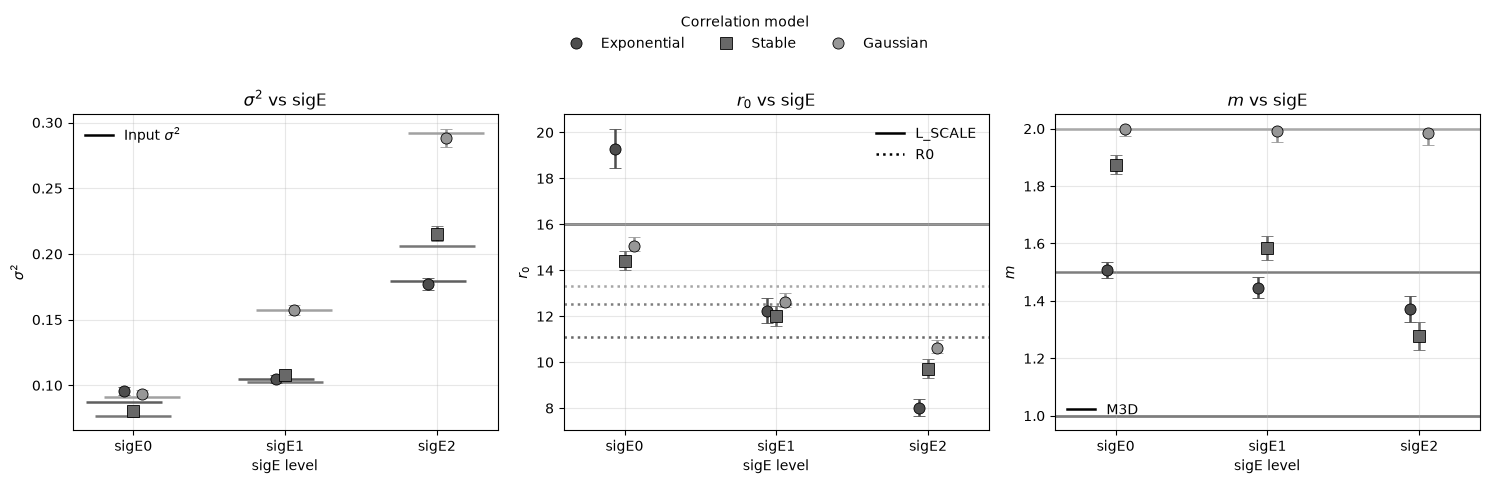

In [10]:
fig, axes = ppu.plot_gstools_params_sigE(
    data_in,
    params=("sig2", "r0", "m"),
    model_order=("exponential", "stable", "gaussian"),
    sigE_levels=(0, 1, 2),
    model_references=model_references,
    figsize=(15, 4.5),
    markersize=8,
    jitter=0.06,
    reference_halfwidth=0.25,
    save=False,
)